In [1]:
from torch.utils.data import Dataset, DataLoader
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df1 = pd.read_csv(r'../data/diamonds.csv', index_col=0)
df2 = pd.read_csv(r'../data/csgo_task.csv')

In [3]:
df1.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
1,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
2,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
3,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
4,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
5,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [4]:
df2.head()

,time_left,ct_score,t_score,map,bomb_planted,ct_health,t_health,ct_armor,t_armor,ct_money,t_money,ct_helmets,t_helmets,ct_defuse_kits,ct_players_alive,t_players_alive
0,175.00,0.0,0.0,de_dust2,False,500.0,500.0,0.0,0.0,4000.0,4000.0,0.0,0.0,0.0,5.0,5.0
1,156.03,0.0,0.0,de_dust2,False,500.0,500.0,400.0,300.0,600.0,650.0,0.0,0.0,1.0,5.0,5.0
2,96.03,0.0,0.0,de_dust2,False,391.0,400.0,294.0,200.0,750.0,500.0,0.0,0.0,1.0,4.0,4.0
3,76.03,0.0,0.0,de_dust2,False,391.0,400.0,294.0,200.0,750.0,500.0,0.0,0.0,1.0,4.0,4.0
4,174.97,1.0,0.0,de_dust2,False,500.0,500.0,192.0,0.0,18350.0,10750.0,0.0,0.0,1.0,5.0,5.0


In [5]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 53940 entries, 1 to 53940
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53940 non-null  float64
 1   cut      53940 non-null  object 
 2   color    53940 non-null  object 
 3   clarity  53940 non-null  object 
 4   depth    53940 non-null  float64
 5   table    53940 non-null  float64
 6   price    53940 non-null  int64  
 7   x        53940 non-null  float64
 8   y        53940 non-null  float64
 9   z        53940 non-null  float64
dtypes: float64(6), int64(1), object(3)
memory usage: 4.5+ MB


In [6]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122410 entries, 0 to 122409
Data columns (total 16 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   time_left         122410 non-null  float64
 1   ct_score          122410 non-null  float64
 2   t_score           121386 non-null  float64
 3   map               122199 non-null  object 
 4   bomb_planted      122410 non-null  bool   
 5   ct_health         122410 non-null  float64
 6   t_health          121627 non-null  float64
 7   ct_armor          122410 non-null  float64
 8   t_armor           122410 non-null  float64
 9   ct_money          122410 non-null  float64
 10  t_money           122410 non-null  float64
 11  ct_helmets        121766 non-null  float64
 12  t_helmets         121560 non-null  float64
 13  ct_defuse_kits    121766 non-null  float64
 14  ct_players_alive  122410 non-null  float64
 15  t_players_alive   122182 non-null  float64
dtypes: bool(1), float64(

# Преобразуем категориальные признаки в датасете на регрессию

In [7]:
df1['cut'].value_counts()

cut
Ideal        21551
Premium      13791
Very Good    12082
Good          4906
Fair          1610
Name: count, dtype: int64

In [8]:
cut_conditions = ['Fair', 'Good', 'Very Good', 'Premium', 'Ideal']
cut_conditions = {cut_conditions[i-1]: i for i in range(1, len(cut_conditions) + 1)}
df1['cut'] = df1['cut'].map(cut_conditions)

In [9]:
df1.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
1,0.23,5,E,SI2,61.5,55.0,326,3.95,3.98,2.43
2,0.21,4,E,SI1,59.8,61.0,326,3.89,3.84,2.31
3,0.23,2,E,VS1,56.9,65.0,327,4.05,4.07,2.31
4,0.29,4,I,VS2,62.4,58.0,334,4.20,4.23,2.63
5,0.31,2,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [10]:
df1['color'].value_counts()

color
G    11292
E     9797
F     9542
H     8304
D     6775
I     5422
J     2808
Name: count, dtype: int64

In [11]:
colors = ['J', 'I', 'H', 'G', 'F', 'E', 'D']
colors = {colors[i-1]: i for i in range(1, len(colors) + 1)}
df1['color'] = df1['color'].map(colors)

In [12]:
df1.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
1,0.23,5,6,SI2,61.5,55.0,326,3.95,3.98,2.43
2,0.21,4,6,SI1,59.8,61.0,326,3.89,3.84,2.31
3,0.23,2,6,VS1,56.9,65.0,327,4.05,4.07,2.31
4,0.29,4,2,VS2,62.4,58.0,334,4.20,4.23,2.63
5,0.31,2,1,SI2,63.3,58.0,335,4.34,4.35,2.75


In [13]:
df1['clarity'].value_counts()

clarity
SI1     13065
VS2     12258
SI2      9194
VS1      8171
VVS2     5066
VVS1     3655
IF       1790
I1        741
Name: count, dtype: int64

In [14]:
clarities = ['I1', 'SI2', 'SI1', 'VS2', 'VS1', 'VVS2', 'VVS1', 'IF']
clarities = {clarities[i-1]: i for i in range(1, len(clarities) + 1)}
df1['clarity'] = df1['clarity'].map(clarities)

In [15]:
df1.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
1,0.23,5,6,2,61.5,55.0,326,3.95,3.98,2.43
2,0.21,4,6,3,59.8,61.0,326,3.89,3.84,2.31
3,0.23,2,6,5,56.9,65.0,327,4.05,4.07,2.31
4,0.29,4,2,4,62.4,58.0,334,4.20,4.23,2.63
5,0.31,2,1,2,63.3,58.0,335,4.34,4.35,2.75


In [16]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 53940 entries, 1 to 53940
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53940 non-null  float64
 1   cut      53940 non-null  int64  
 2   color    53940 non-null  int64  
 3   clarity  53940 non-null  int64  
 4   depth    53940 non-null  float64
 5   table    53940 non-null  float64
 6   price    53940 non-null  int64  
 7   x        53940 non-null  float64
 8   y        53940 non-null  float64
 9   z        53940 non-null  float64
dtypes: float64(6), int64(4)
memory usage: 4.5 MB


In [17]:
df1.describe()

,carat,cut,color,clarity,depth,table,price,x,y,z
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,0.797940,3.904097,4.405803,4.051020,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,0.474011,1.116600,1.701105,1.647136,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,0.200000,1.000000,1.000000,1.000000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.400000,3.000000,3.000000,3.000000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,0.700000,4.000000,4.000000,4.000000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.040000,5.000000,6.000000,5.000000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,5.010000,5.000000,7.000000,8.000000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


In [18]:
df1 = df1.drop(df1[(df1['x'] == 0) | (df1['y'] == 0) | (df1['z'] == 0)].index)

In [19]:
df1.describe()

,carat,cut,color,clarity,depth,table,price,x,y,z
count,53920.000000,53920.000000,53920.000000,53920.000000,53920.000000,53920.000000,53920.000000,53920.000000,53920.000000,53920.000000
mean,0.797698,3.904228,4.405972,4.051502,61.749514,57.456834,3930.993231,5.731627,5.734887,3.540046
std,0.473795,1.116579,1.701272,1.647005,1.432331,2.234064,3987.280446,1.119423,1.140126,0.702530
min,0.200000,1.000000,1.000000,1.000000,43.000000,43.000000,326.000000,3.730000,3.680000,1.070000
25%,0.400000,3.000000,3.000000,3.000000,61.000000,56.000000,949.000000,4.710000,4.720000,2.910000
50%,0.700000,4.000000,4.000000,4.000000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.040000,5.000000,6.000000,5.000000,62.500000,59.000000,5323.250000,6.540000,6.540000,4.040000
max,5.010000,5.000000,7.000000,8.000000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


In [20]:
df1[df1['price'] == df1['price'].max()]

,carat,cut,color,clarity,depth,table,price,x,y,z
27750,2.29,4,2,4,60.8,60.0,18823,8.5,8.47,5.16


In [21]:
df1[df1['price'] == df1['price'].min()]

,carat,cut,color,clarity,depth,table,price,x,y,z
1,0.23,5,6,2,61.5,55.0,326,3.95,3.98,2.43
2,0.21,4,6,3,59.8,61.0,326,3.89,3.84,2.31


## Пустые значения

In [22]:
(df1.isna().sum()/df1.shape[0]*100).sort_values(ascending=False)

carat      0.0
cut        0.0
color      0.0
clarity    0.0
depth      0.0
table      0.0
price      0.0
x          0.0
y          0.0
z          0.0
dtype: float64

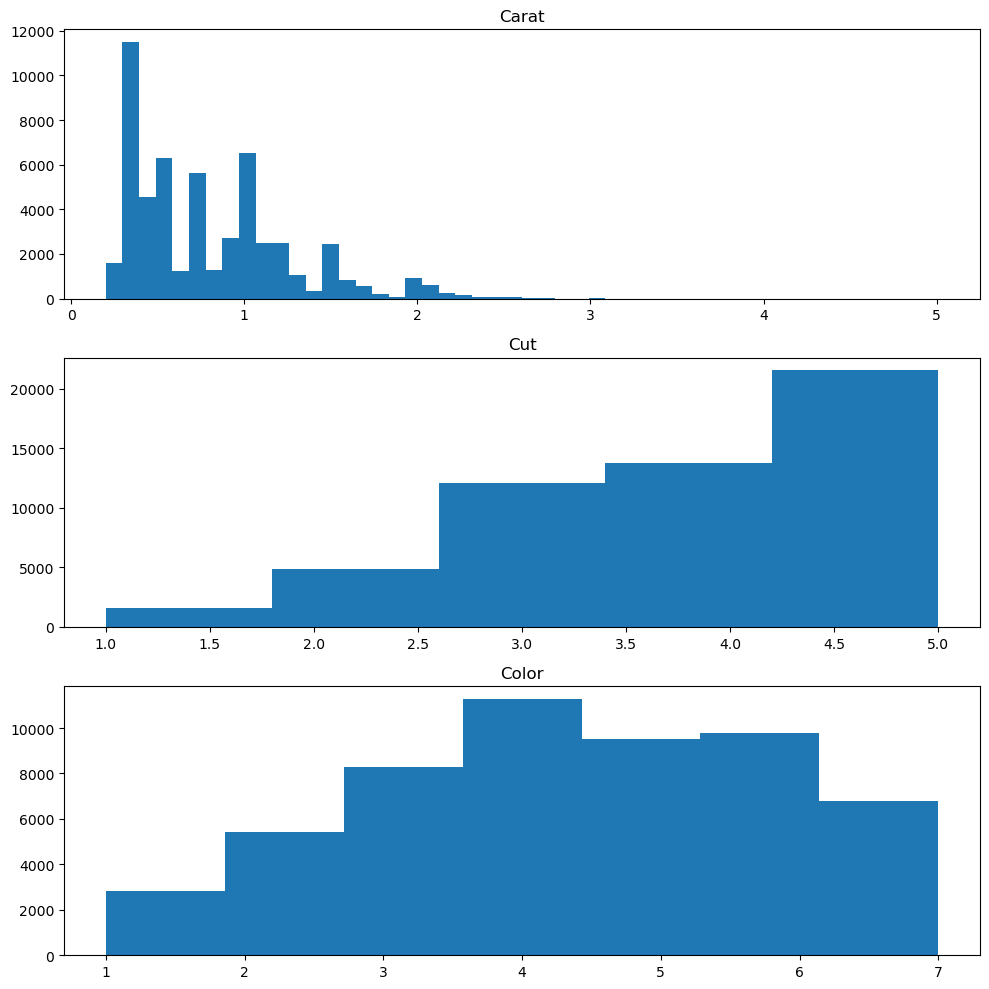

In [23]:
fig, axs = plt.subplots(3, 1, tight_layout=True, figsize=(10, 10))

axs[0].hist(df1['carat'], bins=50)
axs[0].set_title('Carat')

axs[1].hist(df1['cut'], bins=5)
axs[1].set_title('Cut')

axs[2].hist(df1['color'], bins=7)
axs[2].set_title('Color')

plt.show()

In [24]:
df1[df1['carat'] >= 3].sort_values(by='price', ascending=False)

,carat,cut,color,clarity,depth,table,price,x,y,z
27686,3.01,4,1,2,59.7,58.0,18710,9.41,9.32,5.59
27685,3.01,4,1,2,60.7,59.0,18710,9.35,9.22,5.64
27680,3.51,4,1,4,62.5,59.0,18701,9.66,9.63,6.03
27650,3.01,2,3,2,57.6,64.0,18593,9.44,9.38,5.42
27639,3.04,4,2,2,59.3,60.0,18559,9.51,9.46,5.62
27631,4.50,1,1,1,65.8,58.0,18531,10.23,10.16,6.72
27516,3.01,1,2,2,65.8,56.0,18242,8.99,8.94,5.90
27517,3.01,1,2,2,65.8,56.0,18242,8.99,8.94,5.90
27515,3.01,4,2,2,60.2,59.0,18242,9.36,9.31,5.62
27519,3.01,2,2,2,63.9,60.0,18242,9.06,9.01,5.77


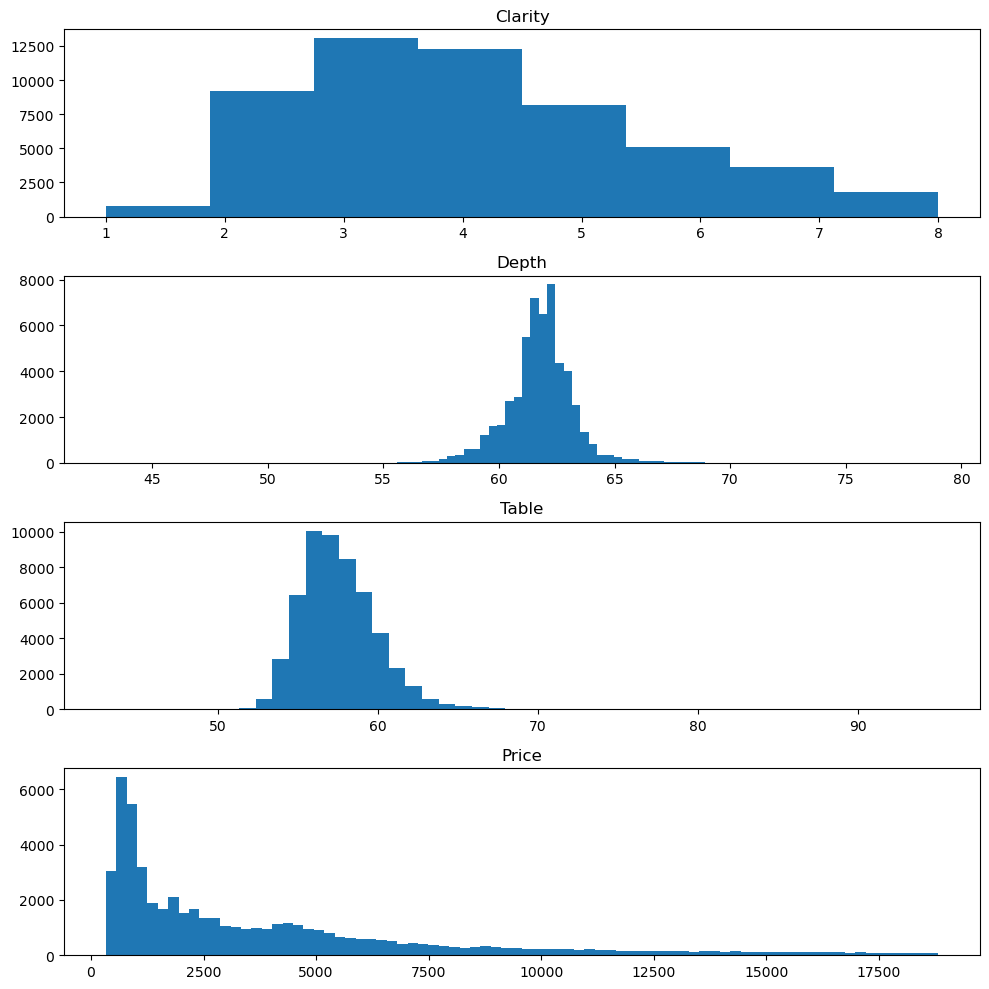

In [25]:
fig, axs = plt.subplots(4, 1, tight_layout=True, figsize=(10, 10))

axs[0].hist(df1['clarity'], bins=8)
axs[0].set_title('Clarity')

axs[1].hist(df1['depth'], bins=100)
axs[1].set_title('Depth')

axs[2].hist(df1['table'], bins=50)
axs[2].set_title('Table')

axs[3].hist(df1['price'], bins='auto')
axs[3].set_title('Price')

plt.show()

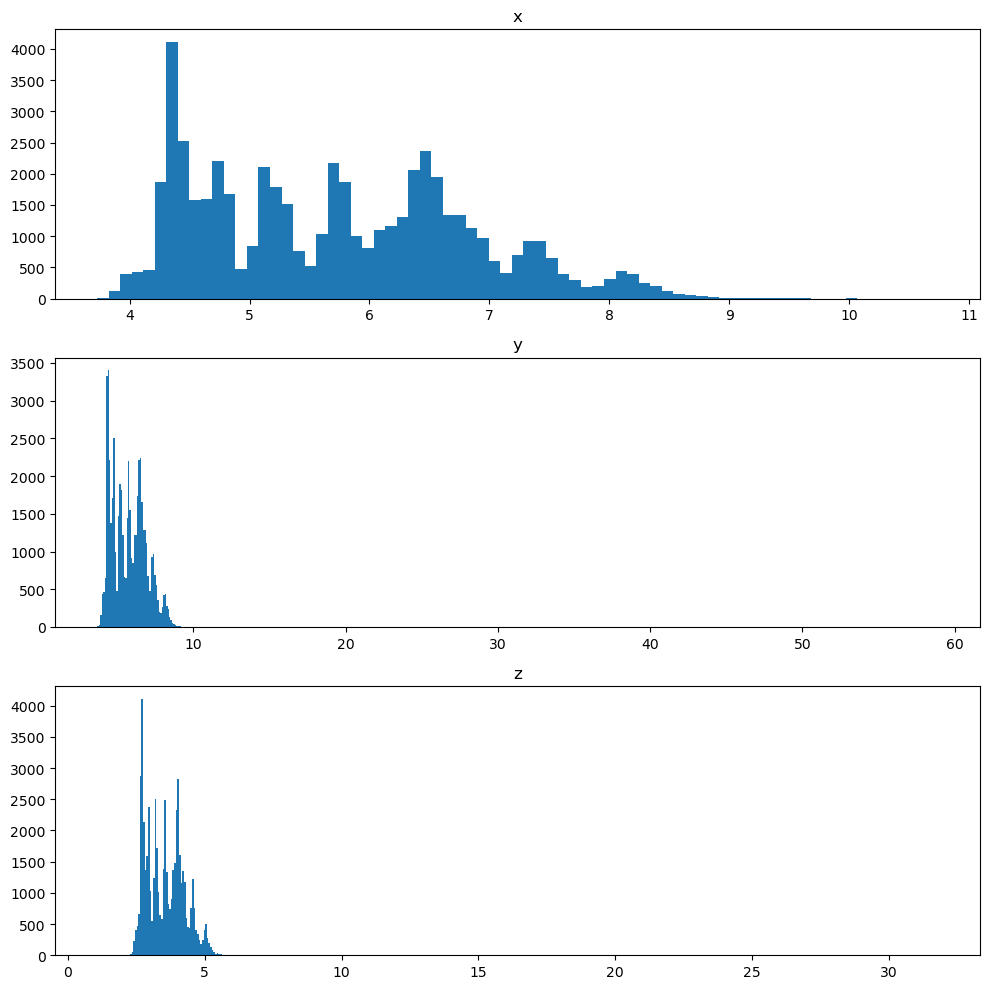

In [26]:
fig, axs = plt.subplots(3, 1, tight_layout=True, figsize=(10, 10))

axs[0].hist(df1['x'], bins='auto')
axs[0].set_title('x')

axs[1].hist(df1['y'], bins='auto')
axs[1].set_title('y')

axs[2].hist(df1['z'], bins='auto')
axs[2].set_title('z')

plt.show()

In [27]:
df1[df1['x'] > 10]

,carat,cut,color,clarity,depth,table,price,x,y,z
25999,4.01,4,2,1,61.0,61.0,15223,10.14,10.10,6.17
26000,4.01,4,1,1,62.5,62.0,15223,10.02,9.94,6.24
26445,4.00,3,2,1,63.3,58.0,15984,10.01,9.94,6.31
27416,5.01,1,1,1,65.5,59.0,18018,10.74,10.54,6.98
27631,4.50,1,1,1,65.8,58.0,18531,10.23,10.16,6.72


In [28]:
df1[df1['y'] > 10]

,carat,cut,color,clarity,depth,table,price,x,y,z
24068,2.00,4,3,2,58.9,57.0,12210,8.09,58.90,8.06
25999,4.01,4,2,1,61.0,61.0,15223,10.14,10.10,6.17
27416,5.01,1,1,1,65.5,59.0,18018,10.74,10.54,6.98
27631,4.50,1,1,1,65.8,58.0,18531,10.23,10.16,6.72
49190,0.51,5,6,5,61.8,55.0,2075,5.15,31.80,5.12


In [29]:
df1[df1['z'] > 7]

,carat,cut,color,clarity,depth,table,price,x,y,z
24068,2.00,4,3,2,58.9,57.0,12210,8.09,58.90,8.06
48411,0.51,3,6,5,61.8,54.7,1970,5.12,5.15,31.80


In [30]:
df1[df1['x'] < 3]

,carat,cut,color,clarity,depth,table,price,x,y,z


In [31]:
df1[df1['y'] < 2]

,carat,cut,color,clarity,depth,table,price,x,y,z


In [32]:
df1[df1['z'] < 2]

,carat,cut,color,clarity,depth,table,price,x,y,z
14636,1.07,5,5,3,60.6,57.0,5909,6.62,6.67,1.07
20695,1.53,5,2,3,61.9,54.0,8971,7.43,7.50,1.53
21655,1.41,5,3,5,60.7,56.0,9752,7.31,7.22,1.41


In [33]:
df1 = df1.drop(df1[(df1['y'] > 11) | (df1['z'] > 10)].index)

In [34]:
outlier = df1[['depth', 'table']]
Q1 = outlier.quantile(0.25)
Q3 = outlier.quantile(0.75)
IQR = Q3 - Q1
data_filtered1 = outlier[~((outlier < (Q1 - 1.5 * IQR)) | (outlier > (Q3 + 1.5 * IQR))).any(axis=1)]
index_list = list(data_filtered1.index.values)
data_filtered1 = df1[df1.index.isin(index_list)]
data_filtered1 = data_filtered1.drop_duplicates()
data_filtered1.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
1,0.23,5,6,2,61.5,55.0,326,3.95,3.98,2.43
2,0.21,4,6,3,59.8,61.0,326,3.89,3.84,2.31
4,0.29,4,2,4,62.4,58.0,334,4.20,4.23,2.63
5,0.31,2,1,2,63.3,58.0,335,4.34,4.35,2.75
6,0.24,3,1,6,62.8,57.0,336,3.94,3.96,2.48


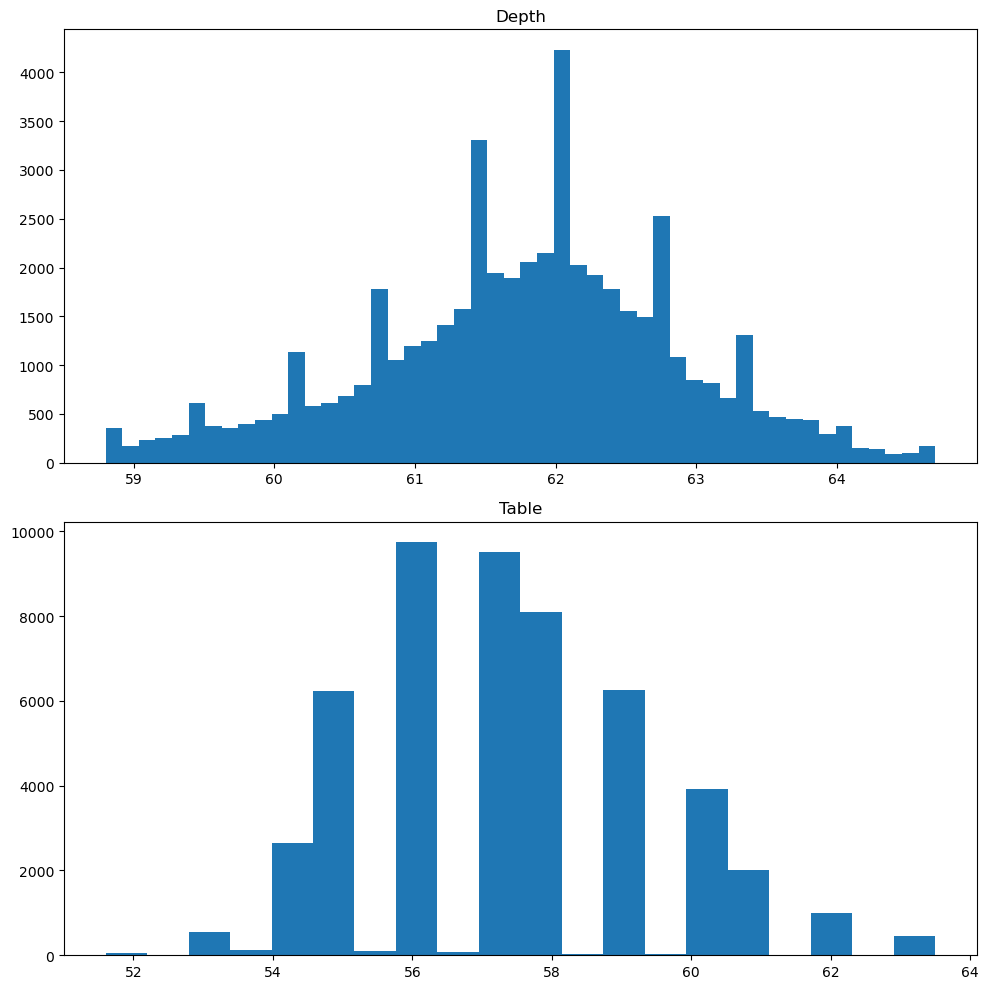

In [35]:
fig, axs = plt.subplots(2, 1, tight_layout=True, figsize=(10, 10))

axs[0].hist(data_filtered1['depth'], bins=50)
axs[0].set_title('Depth')

axs[1].hist(data_filtered1['table'], bins=20)
axs[1].set_title('Table')

plt.show()

# Предобработка 2 датасета

In [36]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122410 entries, 0 to 122409
Data columns (total 16 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   time_left         122410 non-null  float64
 1   ct_score          122410 non-null  float64
 2   t_score           121386 non-null  float64
 3   map               122199 non-null  object 
 4   bomb_planted      122410 non-null  bool   
 5   ct_health         122410 non-null  float64
 6   t_health          121627 non-null  float64
 7   ct_armor          122410 non-null  float64
 8   t_armor           122410 non-null  float64
 9   ct_money          122410 non-null  float64
 10  t_money           122410 non-null  float64
 11  ct_helmets        121766 non-null  float64
 12  t_helmets         121560 non-null  float64
 13  ct_defuse_kits    121766 non-null  float64
 14  ct_players_alive  122410 non-null  float64
 15  t_players_alive   122182 non-null  float64
dtypes: bool(1), float64(

In [37]:
(df2.isna().sum()/df2.shape[0]*100).sort_values(ascending=False)

t_score             0.836533
t_helmets           0.694388
t_health            0.639654
ct_helmets          0.526101
ct_defuse_kits      0.526101
t_players_alive     0.186259
map                 0.172372
ct_score            0.000000
ct_armor            0.000000
ct_health           0.000000
bomb_planted        0.000000
time_left           0.000000
t_money             0.000000
ct_money            0.000000
t_armor             0.000000
ct_players_alive    0.000000
dtype: float64

In [38]:
df2.shape

(122410, 16)

In [39]:
df2['map'].value_counts()

map
de_inferno     23768
de_dust2       22101
de_nuke        18997
de_mirage      18547
de_overpass    14056
de_train       13471
de_vertigo     11115
de_cache         144
Name: count, dtype: int64

In [40]:
df2 = df2.dropna()

In [41]:
(df2.isna().sum()/df2.shape[0]*100).sort_values(ascending=False)

time_left           0.0
ct_score            0.0
t_score             0.0
map                 0.0
bomb_planted        0.0
ct_health           0.0
t_health            0.0
ct_armor            0.0
t_armor             0.0
ct_money            0.0
t_money             0.0
ct_helmets          0.0
t_helmets           0.0
ct_defuse_kits      0.0
ct_players_alive    0.0
t_players_alive     0.0
dtype: float64

In [42]:
df2.shape

(118089, 16)

In [43]:
df2.head()

,time_left,ct_score,t_score,map,bomb_planted,ct_health,t_health,ct_armor,t_armor,ct_money,t_money,ct_helmets,t_helmets,ct_defuse_kits,ct_players_alive,t_players_alive
0,175.00,0.0,0.0,de_dust2,False,500.0,500.0,0.0,0.0,4000.0,4000.0,0.0,0.0,0.0,5.0,5.0
1,156.03,0.0,0.0,de_dust2,False,500.0,500.0,400.0,300.0,600.0,650.0,0.0,0.0,1.0,5.0,5.0
2,96.03,0.0,0.0,de_dust2,False,391.0,400.0,294.0,200.0,750.0,500.0,0.0,0.0,1.0,4.0,4.0
3,76.03,0.0,0.0,de_dust2,False,391.0,400.0,294.0,200.0,750.0,500.0,0.0,0.0,1.0,4.0,4.0
4,174.97,1.0,0.0,de_dust2,False,500.0,500.0,192.0,0.0,18350.0,10750.0,0.0,0.0,1.0,5.0,5.0


In [44]:
df2['map'].value_counts()

map
de_inferno     22986
de_dust2       21391
de_nuke        18298
de_mirage      17903
de_overpass    13607
de_train       13008
de_vertigo     10758
de_cache         138
Name: count, dtype: int64

In [45]:
df2 = pd.get_dummies(df2, columns=['map']).astype(int)
df2.head()

,time_left,ct_score,t_score,bomb_planted,ct_health,t_health,ct_armor,t_armor,ct_money,t_money,...,ct_players_alive,t_players_alive,map_de_cache,map_de_dust2,map_de_inferno,map_de_mirage,map_de_nuke,map_de_overpass,map_de_train,map_de_vertigo
0,175,0,0,0,500,500,0,0,4000,4000,...,5,5,0,1,0,0,0,0,0,0
1,156,0,0,0,500,500,400,300,600,650,...,5,5,0,1,0,0,0,0,0,0
2,96,0,0,0,391,400,294,200,750,500,...,4,4,0,1,0,0,0,0,0,0
3,76,0,0,0,391,400,294,200,750,500,...,4,4,0,1,0,0,0,0,0,0
4,174,1,0,0,500,500,192,0,18350,10750,...,5,5,0,1,0,0,0,0,0,0


In [46]:
df2['bomb_planted'] = df2['bomb_planted'].astype(int)

In [47]:
columns = ['ct_score', 't_score', 'ct_health', 't_health', 'ct_armor', 't_armor', 'ct_money',	't_money', 'ct_helmets', 't_helmets', 'ct_defuse_kits', 'ct_players_alive', 't_players_alive']
df2[columns].describe()

,ct_score,t_score,ct_health,t_health,ct_armor,t_armor,ct_money,t_money,ct_helmets,t_helmets,ct_defuse_kits,ct_players_alive,t_players_alive
count,118089.000000,118089.000000,118089.000000,118089.000000,118089.000000,118089.000000,118089.000000,118089.000000,118089.000000,118089.000000,118089.000000,118089.000000,118089.000000
mean,6.710413,6.784078,412.117953,402.656615,314.150116,298.407684,9791.605907,11241.443318,2.054366,2.773332,1.614138,4.273760,4.265342
std,4.789464,4.822934,132.221112,139.975464,171.013700,174.624505,11218.212318,12171.961305,1.841703,2.010738,1.605528,1.205018,1.229189
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.000000,3.000000,350.000000,321.000000,194.000000,174.000000,1300.000000,1550.000000,0.000000,0.000000,0.000000,4.000000,4.000000
50%,6.000000,6.000000,500.000000,500.000000,377.000000,334.000000,5500.000000,7150.000000,2.000000,3.000000,1.000000,5.000000,5.000000
75%,10.000000,10.000000,500.000000,500.000000,486.000000,468.000000,14600.000000,18000.000000,4.000000,5.000000,3.000000,5.000000,5.000000
max,32.000000,33.000000,500.000000,600.000000,500.000000,500.000000,80000.000000,80000.000000,5.000000,5.000000,5.000000,5.000000,6.000000


In [48]:
df2[df2['t_players_alive'] == 6]

,time_left,ct_score,t_score,bomb_planted,ct_health,t_health,ct_armor,t_armor,ct_money,t_money,...,ct_players_alive,t_players_alive,map_de_cache,map_de_dust2,map_de_inferno,map_de_mirage,map_de_nuke,map_de_overpass,map_de_train,map_de_vertigo
58271,175,0,0,0,400,600,0,0,3200,4800,...,4,6,0,0,0,0,0,0,0,1


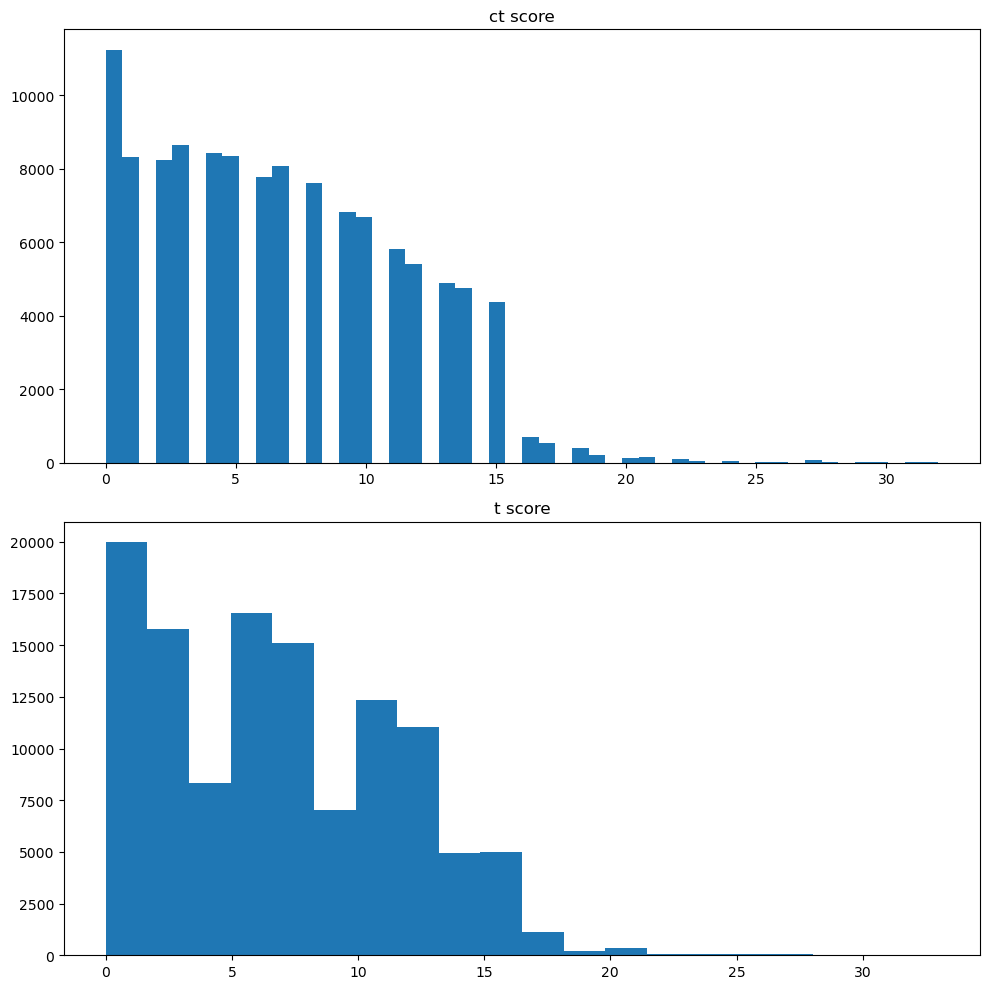

In [49]:
fig, axs = plt.subplots(2, 1, tight_layout=True, figsize=(10, 10))

axs[0].hist(df2['ct_score'], bins=50)
axs[0].set_title('ct score')

axs[1].hist(df2['t_score'], bins=20)
axs[1].set_title('t score')

plt.show()

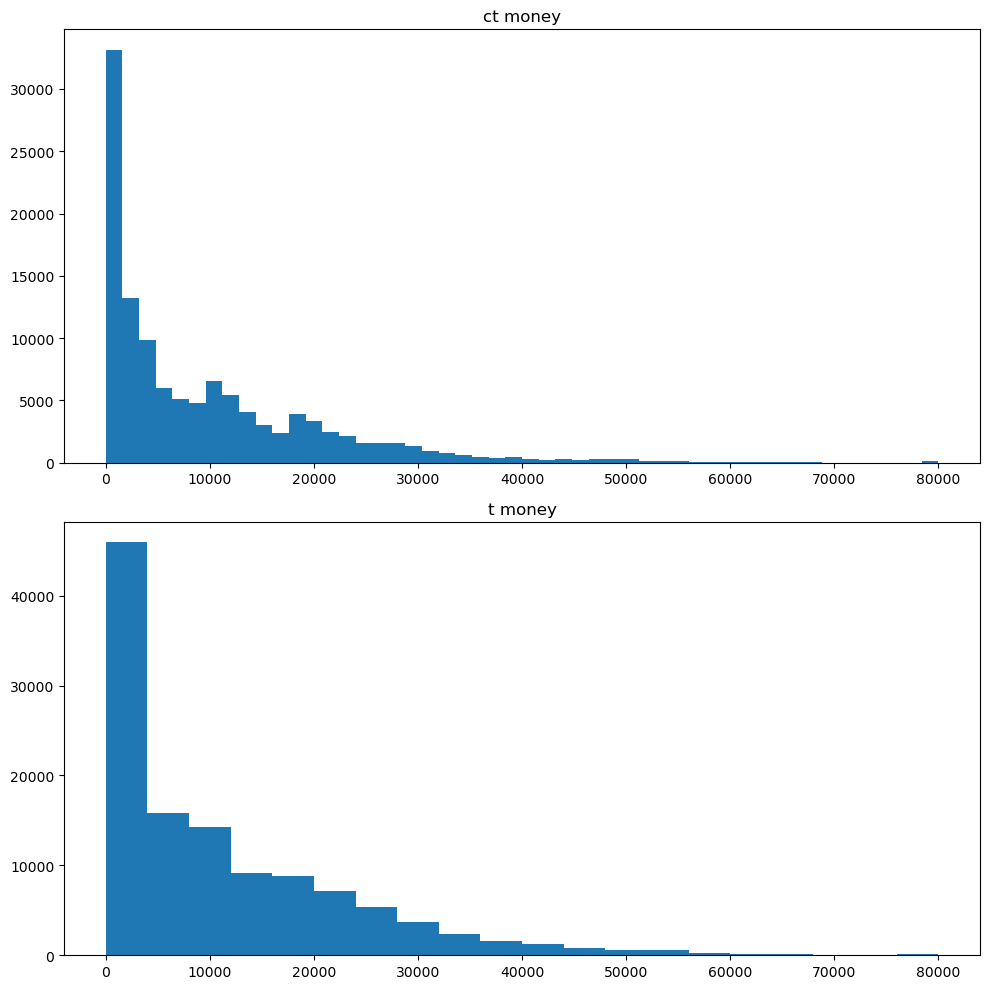

In [50]:
fig, axs = plt.subplots(2, 1, tight_layout=True, figsize=(10, 10))

axs[0].hist(df2['ct_money'], bins=50)
axs[0].set_title('ct money')

axs[1].hist(df2['t_money'], bins=20)
axs[1].set_title('t money')

plt.show()

In [51]:
df2 = df2.drop(df2[df2['t_players_alive'] > 5].index)

In [52]:
df2[columns].describe()

,ct_score,t_score,ct_health,t_health,ct_armor,t_armor,ct_money,t_money,ct_helmets,t_helmets,ct_defuse_kits,ct_players_alive,t_players_alive
count,118088.000000,118088.000000,118088.000000,118088.000000,118088.000000,118088.000000,118088.000000,118088.000000,118088.000000,118088.000000,118088.000000,118088.000000,118088.000000
mean,6.710470,6.784136,412.118056,402.654944,314.152776,298.410211,9791.661727,11241.497866,2.054383,2.773355,1.614152,4.273762,4.265328
std,4.789444,4.822914,132.221667,139.974878,171.011980,174.623086,11218.243418,12171.998409,1.841701,2.010730,1.605528,1.205023,1.229184
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.000000,3.000000,350.000000,321.000000,194.000000,174.000000,1300.000000,1550.000000,0.000000,0.000000,0.000000,4.000000,4.000000
50%,6.000000,6.000000,500.000000,500.000000,377.000000,334.000000,5500.000000,7150.000000,2.000000,3.000000,1.000000,5.000000,5.000000
75%,10.000000,10.000000,500.000000,500.000000,486.000000,468.000000,14600.000000,18000.000000,4.000000,5.000000,3.000000,5.000000,5.000000
max,32.000000,33.000000,500.000000,500.000000,500.000000,500.000000,80000.000000,80000.000000,5.000000,5.000000,5.000000,5.000000,5.000000


In [53]:
df2 = df2.drop_duplicates()

In [54]:
data_filtered1.to_csv(r'../data/diamonds_filtered.csv')
df2.to_csv(r'../data/csgo_filetred.csv')